# Регресійна задача з однією змінною(ознакою):
# $y = wx + b$

# Множинна регресія(регресійна задача з кількома змінними):
# $y = w1x1 + w2x2 + ... + wnxn + b$


# Задача 1: Прогнозувати витрату палива автомобіля(літрів/100 км) за наступними параметрами:
* Об'єм двигуна(у літрах)
* Вага автомобіля(у кілограмах)
* Потужність двигуна (у кінських силах)

In [133]:
import numpy as np
import pandas as pd

In [134]:
cars_count = 300

In [135]:
engine_size = np.random.uniform(1.0, 5.0, cars_count)
weight = np.random.uniform(1000, 2500, cars_count)
horse_power = np.random.uniform(70, 350, cars_count)

In [136]:
fuel_consumption = (
    3.0 + (engine_size * 1.5) + (weight * 0.002) + (horse_power * 0.01) + np.random.normal(0, 1.5, size=cars_count)
)

In [137]:
df = pd.DataFrame({
    "EngineSize": engine_size,
    "Weight": weight,
    "HorsePower": horse_power,
    "FuelConsumption": fuel_consumption
})

df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,3.754474,1987.336113,211.544348,11.361040
1,1.918715,1876.131493,286.139264,14.562708
2,4.343281,1525.614790,194.775662,16.921380
3,1.179613,1172.416593,277.311450,9.620659
4,3.911185,1794.039206,279.972898,16.185282


In [138]:
df.loc[np.random.choice(cars_count, 15), 'Weight'] = np.nan
df.loc[np.random.choice(cars_count, 10), 'HorsePower'] = np.nan

In [139]:
df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,3.754474,1987.336113,211.544348,11.361040
1,1.918715,NaN,286.139264,14.562708
2,4.343281,1525.614790,194.775662,16.921380
3,1.179613,1172.416593,277.311450,9.620659
4,3.911185,NaN,279.972898,16.185282


In [140]:
df.loc[12, 'FuelConsumption'] = 45

In [141]:
df.loc[45, 'Weight'] = 12000.0

In [142]:
df.loc[88, 'EngineSize'] = -2.0

In [143]:
df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,3.754474,1987.336113,211.544348,11.361040
1,1.918715,NaN,286.139264,14.562708
2,4.343281,1525.614790,194.775662,16.921380
3,1.179613,1172.416593,277.311450,9.620659
4,3.911185,NaN,279.972898,16.185282


In [144]:
df = df[(df['EngineSize'] > 0) & (df['Weight'] < 6000)]

In [145]:
len(df)

283

In [146]:
from sklearn.impute import SimpleImputer

In [147]:
# замінює nan значеннями
imputer = SimpleImputer(strategy='median')
df[['EngineSize','Weight','HorsePower', 'FuelConsumption']] = imputer.fit_transform(
    df[['EngineSize','Weight','HorsePower', 'FuelConsumption']]
)

In [148]:
df.head()

,EngineSize,Weight,HorsePower,FuelConsumption
0,3.754474,1987.336113,211.544348,11.361040
2,4.343281,1525.614790,194.775662,16.921380
3,1.179613,1172.416593,277.311450,9.620659
5,4.422454,1530.589458,140.339111,15.567679
6,4.219102,1433.298547,222.728085,10.720936


In [149]:
Q1 = df['FuelConsumption'].quantile(0.25)
Q3 = df['FuelConsumption'].quantile(0.75)
IQR = Q3 - Q1

In [150]:
df = df[(df['FuelConsumption'] >= Q1 - 1.5 *IQR) & (df['FuelConsumption'] <= Q3 + 1.5 * IQR)]

In [151]:
len(df)

281

In [152]:
df[df['FuelConsumption']>18]

,EngineSize,Weight,HorsePower,FuelConsumption
43,4.823084,2496.984950,329.582513,19.573635
53,4.643216,2333.554603,287.817571,18.580506
55,4.764416,1830.804403,276.071035,18.366949
64,4.181088,1658.220017,280.142347,19.672316
115,3.692624,1935.683832,232.599576,18.679995
117,3.976072,2467.776448,193.483374,18.893932
143,4.681991,2267.511982,113.550244,18.058270
221,4.560502,2477.648931,195.142971,18.604006
286,4.984636,1107.298539,203.043563,18.273431


In [153]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [154]:
# features
X = df[['EngineSize', 'Weight', 'HorsePower']]
# target feature
y = df['FuelConsumption']

In [155]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state = 42)

In [156]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [157]:
print(f'Intrcept(b): {model.intercept_:.2f}')

Intrcept(b): 2.41


In [158]:
for feature, coef in zip(X.columns, model.coef_):
  print(f'Feature: {feature}: {coef:.2f}')

Feature: EngineSize: 1.58
Feature: Weight: 0.00
Feature: HorsePower: 0.01


In [159]:
y_pred = model.predict(X_test)
print('Test data count: ', len(y_pred))
y_pred

Test data count:  57


array([17.27945779, 11.46454205, 12.70333827, 11.79872663, 12.62746826,
       14.34744202, 14.91580488, 12.9894872 , 17.70229991, 10.47257913,
       10.9348055 , 11.11094715, 11.50282268, 13.32765322, 11.79023492,
       11.34969357, 11.49764723, 15.3543263 , 16.21441033, 15.65231094,
        9.5645596 , 13.17744271,  9.7399656 , 14.77117354, 11.16650248,
       14.55655137, 11.73576338, 14.11821851, 11.20938544, 11.08521484,
       14.77930097, 11.47508   , 13.07857209, 12.22124516, 15.06109949,
       11.90156354, 13.23927088, 10.71690211, 15.43299621, 13.32421793,
       12.44519607,  9.03583939, 12.94472653, 15.27450366,  8.47095577,
       15.61807942, 13.01028013, 14.38537444, 10.48502138, 11.73882748,
       13.9099971 , 15.94031315, 13.39619855, 13.77728183,  8.82088528,
       15.46199146, 16.16177263])

In [160]:
from sklearn.metrics import r2_score, mean_squared_error

In [161]:
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")
print(f"MAE: {np.sqrt(mse):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.2f}")

MSE: 2.29
MAE: 1.51
R2 Score: 0.69


In [162]:
new_cars = pd.DataFrame({
    'EngineSize': [1.4, 3.5, 2.0],
    'Weight':[1100, 2200, 1400],
    'HorsePower':[95, 300, 150]
})
new_cars.head()

,EngineSize,Weight,HorsePower
0,1.4,1100,95
1,3.5,2200,300
2,2.0,1400,150


In [163]:
predict = model.predict(new_cars)
predict

array([ 7.98318347, 15.78077292, 10.1438351 ])

In [164]:
import matplotlib.pyplot as plt

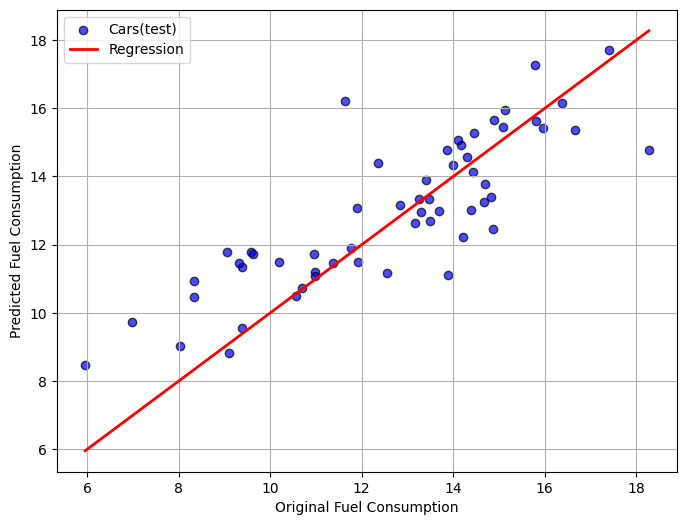

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(
    y_test, y_pred,
    color='blue',
    alpha=0.7,
    edgecolors='k',
    label='Cars(test)'
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='red',
    linewidth=2,
    label='Regression'
)
plt.title = 'Fuel consumption'
plt.legend()
plt.xlabel('Original Fuel Consumption')
plt.ylabel('Predicted Fuel Consumption')
plt.grid(True)
plt.show()